# T4: Uniform weight-sharing NAS
Four blocks each choose one of four operations, so $|\mathcal S|=4^4=256$.
GroupNorm avoids path-dependent BatchNorm running statistics.


In [ ]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "code"))


In [1]:
from common import *
from scipy.stats import kendalltau, rankdata

seed_all(44)
train, val = cifar_data(44)
OPS = ["conv3x3", "conv5x5", "dwsep3x3", "identity"]


## Supernet, path encoding and independent extraction
A path is a tuple of four operation indices. Extraction deep-copies only the
selected operations, plus the shared stem and head.


In [2]:
def operation(index):
    if index == 3:
        return nn.Identity()
    if index == 2:
        conv = nn.Sequential(
            nn.Conv2d(16, 16, 3, padding=1, groups=16, bias=False),
            nn.Conv2d(16, 16, 1, bias=False),
        )
    else:
        k = 3 if index == 0 else 5
        conv = nn.Conv2d(16, 16, k, padding=k // 2, bias=False)
    return nn.Sequential(conv, nn.GroupNorm(4, 16), nn.ReLU())


class Supernet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.GroupNorm(4, 16), nn.ReLU()
        )
        self.blocks = nn.ModuleList(
            [nn.ModuleList([operation(i) for i in range(4)]) for _ in range(4)]
        )
        self.head = nn.Linear(16, 10)

    def forward(self, x, path):
        x = self.stem(x)
        for block, index in zip(self.blocks, path):
            x = block[index](x)
        return self.head(x.mean((2, 3)))


class Subnet(nn.Module):
    def __init__(self, source, path):
        super().__init__()
        self.stem = copy.deepcopy(source.stem)
        self.blocks = nn.ModuleList(
            [copy.deepcopy(block[i]) for block, i in zip(source.blocks, path)]
        )
        self.head = copy.deepcopy(source.head)

    def forward(self, x):
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        return self.head(x.mean((2, 3)))


model = Supernet().to(DEVICE)
rng = random.Random(44)
path_a = (0, 1, 2, 3)
path_b = (0, 2, 2, 1)
x, y = next(iter(loader(train)))
x, y = x.to(DEVICE), y.to(DEVICE)
checks = {
    "paths": [path_a, path_b],
    "active_operations": [[OPS[i] for i in p] for p in [path_a, path_b]],
    "output_shapes": [list(model(x, p).shape) for p in [path_a, path_b]],
    "shared_blocks": [i for i, (a, b) in enumerate(zip(path_a, path_b)) if a == b],
    "identity_parameters": sum(p.numel() for p in operation(3).parameters()),
    "mappings": [
        [f"blocks.{j}.{i} -> subnet.blocks.{j}" for j, i in enumerate(p)]
        for p in [path_a, path_b]
    ],
}
extracted = Subnet(model, path_a).to(DEVICE)
checks["extraction_matches"] = torch.allclose(extracted(x), model(x, path_a))
checks["extraction_independent_storage"] = (
    extracted.stem[0].weight.data_ptr() != model.stem[0].weight.data_ptr()
)
checks["shared_operation_parameter_storage"] = {
    str(j): [p.data_ptr() for p in model.blocks[j][a].parameters()]
    == [p.data_ptr() for p in model.blocks[j][b].parameters()]
    for j, (a, b) in enumerate(zip(path_a, path_b))
}
print(checks)


{'paths': [(0, 1, 2, 3), (0, 2, 2, 1)], 'active_operations': [['conv3x3', 'conv5x5', 'dwsep3x3', 'identity'], ['conv3x3', 'dwsep3x3', 'dwsep3x3', 'conv5x5']], 'output_shapes': [[64, 10], [64, 10]], 'shared_blocks': [0, 2], 'identity_parameters': 0, 'mappings': [['blocks.0.0 -> subnet.blocks.0', 'blocks.1.1 -> subnet.blocks.1', 'blocks.2.2 -> subnet.blocks.2', 'blocks.3.3 -> subnet.blocks.3'], ['blocks.0.0 -> subnet.blocks.0', 'blocks.1.2 -> subnet.blocks.1', 'blocks.2.2 -> subnet.blocks.2', 'blocks.3.1 -> subnet.blocks.3']], 'extraction_matches': True, 'extraction_independent_storage': True, 'shared_operation_parameter_storage': {'0': True, '1': False, '2': True, '3': False}}


## Train for five epochs, sampling one path per minibatch
Setting gradients to None prevents inactive operations from being updated by
optimizer momentum. We check actual parameter values after an optimizer step.


In [3]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
counts = np.zeros((4, 4), dtype=int)
history = []
batches = loader(train, True, 44)
sync()
start = time.perf_counter()
for epoch in range(5):
    model.train()
    total = correct = n = 0
    for step, (x, y) in enumerate(batches):
        path = tuple(rng.randrange(4) for _ in range(4))
        for j, i in enumerate(path):
            counts[j, i] += 1
        before = (
            {k: p.detach().clone() for k, p in model.named_parameters()}
            if epoch == step == 0
            else None
        )
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        z = model(x, path)
        loss = F.cross_entropy(z, y)
        loss.backward()
        optimizer.step()
        if before is not None:
            inactive = []
            active = []
            for key, p in model.named_parameters():
                parts = key.split(".")
                is_active = parts[0] != "blocks" or int(parts[2]) == path[int(parts[1])]
                (active if is_active else inactive).append(
                    not torch.equal(before[key], p)
                )
            checks["inactive_parameters_unchanged"] = not any(inactive)
            checks["active_parameters_changed"] = any(active)
            checks["checked_path"] = path
        total += loss.item() * len(y)
        correct += (z.argmax(1) == y).sum().item()
        n += len(y)
    history.append(
        {
            "epoch": epoch + 1,
            "train": {"loss": total / n, "accuracy": 100 * correct / n},
            "validation": evaluate(model, loader(val), lambda x: model(x, path_a)),
        }
    )
    print(history[-1], flush=True)
sync()
training = {
    "history": history,
    "seconds": time.perf_counter() - start,
    "updates": 5 * len(batches),
}
torch.save(model.state_dict(), ROOT / "checkpoints" / "t4_supernet.pt")


{'epoch': 1, 'train': {'loss': 2.3299526985168457, 'accuracy': 10.06}, 'validation': {'loss': 2.316079391479492, 'accuracy': 10.3}}
{'epoch': 2, 'train': {'loss': 2.3116788997650146, 'accuracy': 10.12}, 'validation': {'loss': 2.3085297393798827, 'accuracy': 10.1}}
{'epoch': 3, 'train': {'loss': 2.3088114795684813, 'accuracy': 9.88}, 'validation': {'loss': 2.3027000579833983, 'accuracy': 12.6}}
{'epoch': 4, 'train': {'loss': 2.3070609451293946, 'accuracy': 10.32}, 'validation': {'loss': 2.305055335998535, 'accuracy': 10.4}}
{'epoch': 5, 'train': {'loss': 2.306924158859253, 'accuracy': 10.1}, 'validation': {'loss': 2.2979116668701174, 'accuracy': 14.0}}


## Twelve independent adaptation runs: 0, 10 and 30 updates
All models start from the same checkpoint. Each gets the same deterministic
minibatch order and optimizer; step 30 continues from step 10.


In [4]:
import itertools

paths = rng.sample(list(itertools.product(range(4), repeat=4)), 12)
adaptation = []
for number, path in enumerate(paths):
    net = Subnet(model, path).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=0.001)
    scores = {"0": evaluate(net, loader(val))["accuracy"]}
    sync()
    start = time.perf_counter()
    for step, (x, y) in enumerate(loader(train, True, 45), start=1):
        net.train()
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        F.cross_entropy(net(x), y).backward()
        opt.step()
        if step in [10, 30]:
            scores[str(step)] = evaluate(net, loader(val))["accuracy"]
        if step == 30:
            break
    sync()
    adaptation.append(
        {"path": path, "accuracy": scores, "seconds": time.perf_counter() - start}
    )
    torch.save(net.state_dict(), ROOT / "checkpoints" / f"t4_adapt_{number+1}.pt")
    print(number + 1, adaptation[-1], flush=True)
scores = {s: [r["accuracy"][s] for r in adaptation] for s in ["0", "10", "30"]}
tau = {
    f"{a}_{b}": float(kendalltau(scores[a], scores[b]).statistic)
    for a, b in [("0", "10"), ("0", "30"), ("10", "30")]
}
ranks = {
    s: rankdata(-np.array(v), method="average").tolist() for s, v in scores.items()
}


1 {'path': (2, 3, 1, 3), 'accuracy': {'0': 10.1, '10': 12.6, '30': 14.2}, 'seconds': 0.8048080999999456}
2 {'path': (2, 1, 1, 2), 'accuracy': {'0': 12.3, '10': 10.2, '30': 13.7}, 'seconds': 1.3200894999999946}
3 {'path': (3, 1, 1, 1), 'accuracy': {'0': 10.0, '10': 12.9, '30': 14.2}, 'seconds': 1.1648113999999623}
4 {'path': (2, 2, 0, 3), 'accuracy': {'0': 10.0, '10': 11.6, '30': 17.0}, 'seconds': 1.0206131999998433}
5 {'path': (2, 1, 0, 0), 'accuracy': {'0': 15.3, '10': 13.6, '30': 14.4}, 'seconds': 1.4510032999999112}
6 {'path': (2, 3, 0, 2), 'accuracy': {'0': 12.3, '10': 12.9, '30': 17.0}, 'seconds': 1.0327755999999226}
7 {'path': (0, 3, 3, 3), 'accuracy': {'0': 12.0, '10': 13.3, '30': 11.9}, 'seconds': 0.48927489999982754}
8 {'path': (0, 2, 3, 2), 'accuracy': {'0': 10.4, '10': 13.5, '30': 19.5}, 'seconds': 0.9298647000000528}
9 {'path': (1, 3, 2, 3), 'accuracy': {'0': 6.4, '10': 11.6, '30': 17.0}, 'seconds': 0.7908844000000954}
10 {'path': (3, 0, 1, 0), 'accuracy': {'0': 12.5, '10':

## Train the best adapted path and a different random path from scratch
Both receive five epochs, Adam at $10^{-3}$, identical seed and data order.


In [5]:
best = int(np.argmax(scores["30"]))
other = rng.choice([i for i in range(12) if i != best])
scratch_runs = {}
for index in [best, other]:
    seed_all(44)
    net = Subnet(Supernet(), paths[index]).to(DEVICE)
    run = fit(net, train, val, 5, 44)
    run["accuracy"] = evaluate(net, loader(val))["accuracy"]
    scratch_runs[str(index + 1)] = run
    torch.save(net.state_dict(), ROOT / "checkpoints" / f"t4_scratch_{index+1}.pt")
result = {
    "checks": checks,
    "training": training,
    "counts": counts.tolist(),
    "adaptation": adaptation,
    "tau": tau,
    "ranks": ranks,
    "best_index": best + 1,
    "random_index": other + 1,
    "scratch": scratch_runs,
}
save_json("task4", result)
print("Kendall tau-b:", tau, "Selected paths:", best + 1, other + 1)


{'epoch': 1, 'train': {'loss': 2.26409690246582, 'accuracy': 15.24}, 'validation': {'loss': 2.2108175201416014, 'accuracy': 20.3}}
{'epoch': 2, 'train': {'loss': 2.143194300842285, 'accuracy': 21.6}, 'validation': {'loss': 2.062004318237305, 'accuracy': 24.4}}
{'epoch': 3, 'train': {'loss': 2.0368322944641113, 'accuracy': 24.84}, 'validation': {'loss': 1.995688102722168, 'accuracy': 26.1}}
{'epoch': 4, 'train': {'loss': 1.9614532627105712, 'accuracy': 27.5}, 'validation': {'loss': 1.9542927780151367, 'accuracy': 27.2}}
{'epoch': 5, 'train': {'loss': 1.8963693084716797, 'accuracy': 29.34}, 'validation': {'loss': 1.8321273651123047, 'accuracy': 29.9}}
{'epoch': 1, 'train': {'loss': 2.280976184463501, 'accuracy': 12.62}, 'validation': {'loss': 2.2365723648071287, 'accuracy': 15.7}}
{'epoch': 2, 'train': {'loss': 2.1399161334991454, 'accuracy': 19.06}, 'validation': {'loss': 2.079269821166992, 'accuracy': 22.0}}
{'epoch': 3, 'train': {'loss': 2.040793208694458, 'accuracy': 22.66}, 'validat

In [6]:
curves(
    {
        "Supernet (fixed validation path)": training,
        **{f"Scratch path {k}": v for k, v in scratch_runs.items()},
    },
    "t4_training",
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, row in enumerate(adaptation):
    color = plt.get_cmap("tab20")(i)
    axes[0].plot(
        [0, 10, 30],
        [row["accuracy"][s] for s in ["0", "10", "30"]],
        marker="o",
        color=color,
        label=str(i + 1),
    )
    axes[1].plot(
        [0, 10, 30], [ranks[s][i] for s in ["0", "10", "30"]], marker="o", color=color
    )
axes[0].set(xlabel="Adaptation updates", ylabel="Validation accuracy (%)")
axes[0].legend(ncol=3, fontsize=7)
axes[1].set(xlabel="Adaptation updates", ylabel="Rank (1 = best)")
axes[1].invert_yaxis()
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t4_adaptation.png", dpi=150)
plt.close(fig)
fig, ax = plt.subplots(figsize=(6, 3))
im = ax.imshow(counts, cmap="Blues")
ax.set(
    xticks=range(4),
    xticklabels=OPS,
    yticks=range(4),
    yticklabels=range(1, 5),
    xlabel="Operation",
    ylabel="Block",
)
for j in range(4):
    for i in range(4):
        ax.text(i, j, str(counts[j, i]), ha="center", va="center")
fig.colorbar(im, ax=ax, label="Sampled minibatches")
ax.tick_params(axis="x", labelsize=8)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "t4_sampling.png", dpi=150)
plt.close(fig)


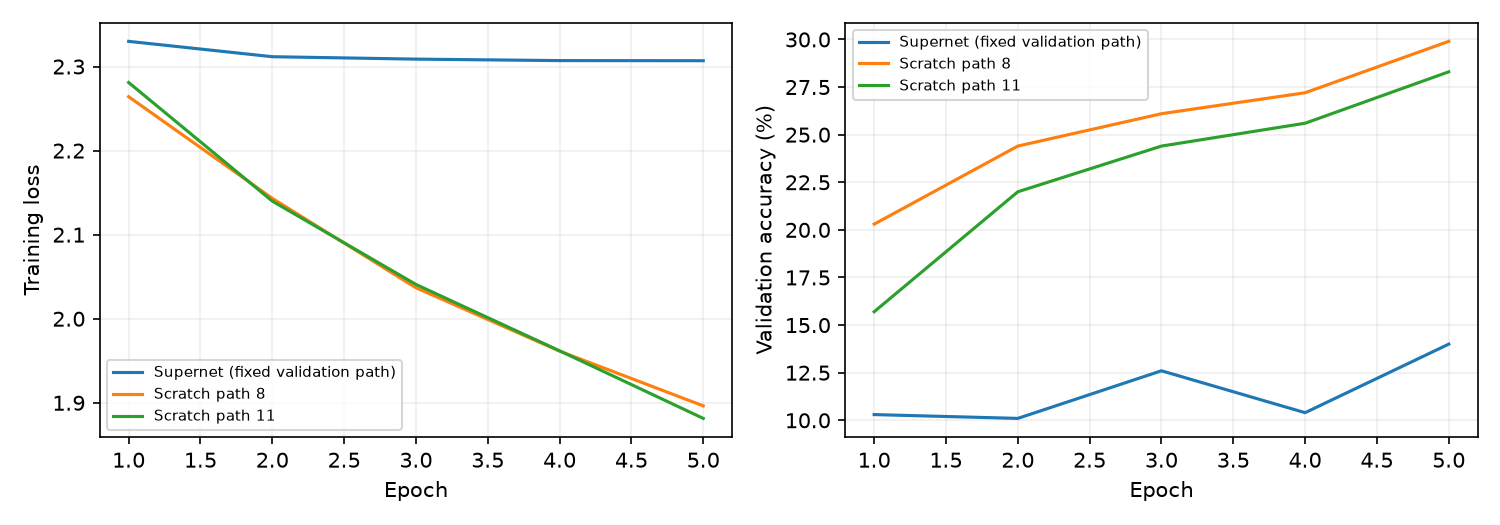

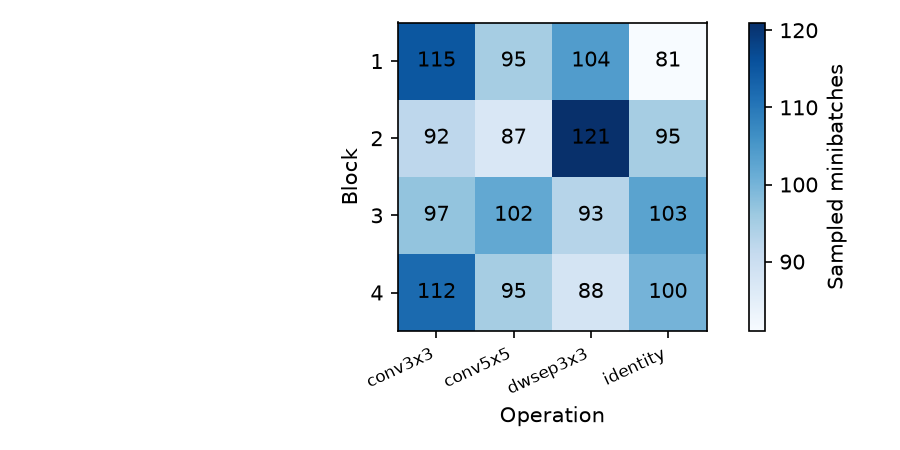

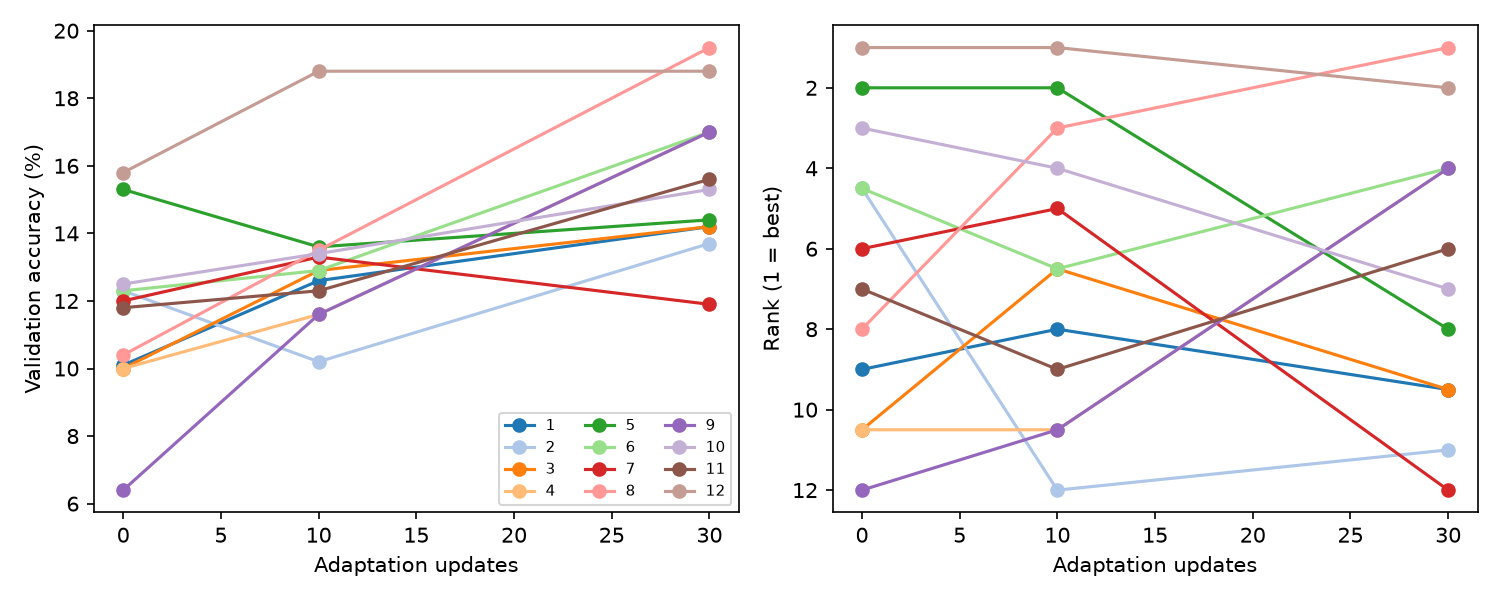

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(project_root / "figures" / "t4_training.png")))
display(Image(filename=str(project_root / "figures" / "t4_sampling.png")))
display(Image(filename=str(project_root / "figures" / "t4_adaptation.png")))


# Analysis

## T4.1: Supernet and Path Sampling

**Q1.** Show two example paths, their active operations, parameter mappings, and output shapes. How does weight sharing reduce the cost of searching a large number of architectures?

**Answer:**

| Path | Active operations | Output shape |
| --- | --- | --- |
| [0, 1, 2, 3] | ['conv3x3', 'conv5x5', 'dwsep3x3', 'identity'] | [64, 10] |
| [0, 2, 2, 1] | ['conv3x3', 'dwsep3x3', 'dwsep3x3', 'conv5x5'] | [64, 10] |

| Verification | Observed value |
| --- | --- |
| shared_blocks | [0, 2] |
| identity_parameters | 0 |
| extraction_matches | True |
| extraction_independent_storage | True |
| inactive_parameters_unchanged | True |
| active_parameters_changed | True |
| checked_path | [3, 0, 1, 3] |
| shared_operation_parameter_storage | {'0': True, '1': False, '2': True, '3': False} |

Mappings: blocks.0.0 -> subnet.blocks.0, blocks.1.1 -> subnet.blocks.1, blocks.2.2 -> subnet.blocks.2, blocks.3.3 -> subnet.blocks.3; blocks.0.0 -> subnet.blocks.0, blocks.1.2 -> subnet.blocks.1, blocks.2.2 -> subnet.blocks.2, blocks.3.1 -> subnet.blocks.3.

Indices 0, 1, 2 and 3 mean conv3x3, conv5x5, depthwise-separable conv3x3 and identity. The example paths share blocks 1 and 3 (one-based), plus the stem and head. Other selected operations use separate tensors. All paths preserve 16 channels and spatial size; the head returns ten logits. Identity has zero parameters. Extraction deep-copies only selected modules: outputs match the supernet path but storage is independent. A fixed stem and four blocks with GroupNorm give 256 paths. Weight sharing replaces hundreds of independent training runs with one pool of reusable operation weights, although the trained weights may favor paths that co-adapt well.


## T4.2: Train the Supernet

**Q1.** Show training curves, training time, parameter-update checks, and sampling counts. What are the advantages and limitations of evaluating architectures using inherited weights?

**Answer:**

The seed-44 stratified split contains 5,000 training and 1,000 validation images from the official training split, disjoint within the task. Every minibatch samples one uniformly random operation per block. Only the selected operations, stem and head execute. Five epochs used Adam at 0.001, batch 64, 395 updates and 12.48 s. Each block's sampling counts sum to 395. Inactive parameters were compared before and after an actual optimizer step and remained unchanged; gradients were reset to None to avoid stale-gradient/momentum updates.

Inherited weights make evaluation inexpensive and place candidates on a shared training budget. However, paths receive unequal combinations of updates, operations interfere and co-adapt, and stand-alone optimization can alter rankings. Uniform operation sampling is not a learned ENAS controller. The validation curve uses one fixed path (0,1,2,3), while training loss averages different sampled paths.

![Supernet training and five-epoch scratch runs for the two selected paths.](../figures/t4_training.png)

Supernet training and five-epoch scratch runs for the two selected paths.

![Observed operation sampling counts by block.](../figures/t4_sampling.png)

Observed operation sampling counts by block.


## T4.3: Subnetwork Adaptation

**Q1.** Show the accuracy table, plots, and Kendall rank correlations. Which subnetworks changed rank? Was the best inherited-weight architecture still the best after adaptation? How much additional training did adaptation require?

**Answer:**

| Path number | Encoding | 0 steps (%) | 10 steps (%) | 30 steps (%) |
| --- | --- | --- | --- | --- |
| 1 | [2, 3, 1, 3] | 10.10 | 12.60 | 14.20 |
| 2 | [2, 1, 1, 2] | 12.30 | 10.20 | 13.70 |
| 3 | [3, 1, 1, 1] | 10.00 | 12.90 | 14.20 |
| 4 | [2, 2, 0, 3] | 10.00 | 11.60 | 17.00 |
| 5 | [2, 1, 0, 0] | 15.30 | 13.60 | 14.40 |
| 6 | [2, 3, 0, 2] | 12.30 | 12.90 | 17.00 |
| 7 | [0, 3, 3, 3] | 12.00 | 13.30 | 11.90 |
| 8 | [0, 2, 3, 2] | 10.40 | 13.50 | 19.50 |
| 9 | [1, 3, 2, 3] | 6.40 | 11.60 | 17.00 |
| 10 | [3, 0, 1, 0] | 12.50 | 13.40 | 15.30 |
| 11 | [1, 0, 1, 0] | 11.80 | 12.30 | 15.60 |
| 12 | [0, 2, 3, 3] | 15.80 | 18.80 | 18.80 |
Each model was independently deep-copied from the same supernet checkpoint, then adapted with Adam at 0.001 on identical seeded training minibatches. Step 30 continues from step 10. No validation minibatch is used for adaptation. Across 12 models, adaptation required 360 optimizer updates and 11.85 s including staged validation. Average ranks handle ties; Kendall tau-b is used.

Kendall correlations: 0 versus 10 steps = 0.5000; 0 versus 30 = -0.0318; 10 versus 30 = 0.1429. Paths changing rank between 0 and 30 steps: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]. Best inherited path: 12; best after 30 steps: 8. Thus the best inherited path did not remain best after adaptation. Full ranks are recorded in `results/task4.json`.

![Validation accuracy trajectories and rankings for the 12 independent subnetworks.](../figures/t4_adaptation.png)

Validation accuracy trajectories and rankings for the 12 independent subnetworks.


## T4.4: Compare With Training From Scratch

**Q1.** Compare inherited, adapted, and independently trained validation accuracy for both architectures. Did adaptation provide a better indication of the final architecture ranking than inherited weights alone?

**Answer:**

| Path | Inherited (%) | Adapted 30 steps (%) | Scratch (%) |
| --- | --- | --- | --- |
| Best adapted: 8 | 10.40 | 19.50 | 29.90 |
| Random: 11 | 11.80 | 15.60 | 28.30 |
Both fresh networks used seed 44, the same minibatch order, optimizer, learning rate and five-epoch budget (395 updates each). Inherited ranking agrees with scratch ranking: False. Adapted ranking agrees with scratch ranking: True. This is a two-architecture comparison only; it cannot establish reliable rank prediction across the whole search space. Scratch wall times were 9.72 s and 12.27 s.
